# Trabalho 1 - Pt.1

## Q1

Dada a função $f(x) = e^{-x} \cdot x(x^2 - x - 1)$, o valor inicial $x_0 = 1$, e a taxa de aprendizagem $\alpha = 0.1$, calcule o próximo valor $x_1$ pela descida de gradiente, usando uma aproximação da derivada pelo método de diferenças finitas (eq. 3.1), com um passo $h = 0.01$.

In [ ]:
import math

# Definindo a função
def f(x):
    return math.exp(-x) * x * (x**2 - x - 1)

# Parâmetros iniciais
x_0 = 1.0
alpha = 0.1
h = 0.01

# Cálculo da aproximação do gradiente por diferenças finitas
gradiente = (f(x_0 + h) - f(x_0)) / h

# Atualização pela descida de gradiente
x_1 = x_0 - alpha * gradiente

# Exibição dos resultados
print(f"Gradiente aproximado: {gradiente:.5f}")
print(f"Próximo valor x_1: {x_1:.5f}")

Gradiente aproximado: 0.37337
Próximo valor x_1: 0.96266


A estimativa do novo ponto $x_1$ foi realizada aplicando o algoritmo de descida de gradiente suportado por uma aproximação numérica da derivada. Utilizando o método de diferenças finitas progressivas com passo $h=0.01$, a inclinação da função $f(x)$ no ponto inicial $x_0=1$ foi avaliada em aproximadamente **0.37337**. 

Como o gradiente é positivo (indicando que a função está crescendo naquele ponto), a regra de atualização matemática desloca a variável na direção oposta, subtraindo o gradiente escalonado pela taxa de aprendizagem ($\alpha=0.1$). Isso resulta no recuo da variável para $x_1 \approx 0.96266$, garantindo o movimento iterativo em direção ao mínimo local da função.

## Q2

Calcule $x_1$ usando a derivada analítica $f'(x)$.

> **Ajuda:** Para calcular a derivada analiticamente, use a função `diff` do pacote `sympy` do Python. A função `lambdify` converte uma função simbólica para uma função numérica.

In [ ]:
import sympy as sp

# Definição da função simbólica
x = sp.Symbol('x')
f_sym = sp.exp(-x) * x * (x**2 - x - 1)

# Cálculo da derivada analítica
df_sym = sp.diff(f_sym, x)

# Conversão da derivada simbólica para uma função numérica
df_num = sp.lambdify(x, df_sym, 'math')

# Definição dos parâmetros
x_0 = 1.0
alpha = 0.1

# Avaliação do gradiente exato e atualização
gradiente_exato = df_num(x_0)
x_1 = x_0 - alpha * gradiente_exato

# Exibição dos resultados
print(f"Derivada simbólica: {df_sym}")
print(f"Gradiente exato em x0=1: {gradiente_exato:.5f}")
print(f"Próximo valor x_1: {x_1:.5f}")

Derivada simbólica: x*(2*x - 1)*exp(-x) - x*(x**2 - x - 1)*exp(-x) + (x**2 - x - 1)*exp(-x)
Gradiente exato em x0=1: 0.36788
Próximo valor x_1: 0.96321


A precisão do cálculo foi aprimorada substituindo a aproximação numérica pela derivada analítica exata, calculada de forma simbólica através da biblioteca `sympy`. 

Ao avaliar o gradiente explícito no ponto inicial $x_0 = 1$, chegamos no valor exato de aproximadamente **0.36788** (matematicamente equivalente a $1/e$). Ao eliminar o erro de truncamento presente no método de diferenças finitas, o gradiente real calculado é ligeiramente menor. Isso reflete na regra de atualização, que produziu um novo passo sutilmente diferente, movendo a variável para $x_1 \approx 0.96321$. 

O uso do gradiente analítico elimina ruídos de aproximação, garantindo uma atualização vetorial mais fiel e uma convergência mais segura na descida de gradiente.

## Q3

Usando o método da **descida de gradiente**, tente aproximar o mínimo de $f$, com o valor inicial $x_0 = 3$ e taxa de aprendizagem $\alpha = 0.1$.

Defina as duas condições de parada do **Algoritmo 3**, com $g_{\min} = 0.1$ e $k_{\max} = 100$.

Qual é o valor do mínimo obtido?

Usando um gráfico bidimensional (eixo $x$ = $x$, eixo $y$ = $f(x)$), marque os valores da aproximação:

$$x_0 \to x_1 \to x_2 \to x_3 \to x_4 \to x_5 \to \cdots$$

$$f(x_0) \to f(x_1) \to f(x_2) \to f(x_3) \to f(x_4) \to f(x_5) \to \cdots$$

$$f'(x_0) \to f'(x_1) \to f'(x_2) \to f'(x_3) \to f'(x_4) \to f'(x_5) \to \cdots$$

Critério de parada atingido: |grad| = 0.0894 na iteração 49
Mínimo aproximado encontrado em x = 0.78494
Valor da função no mínimo f(x) = -0.41849


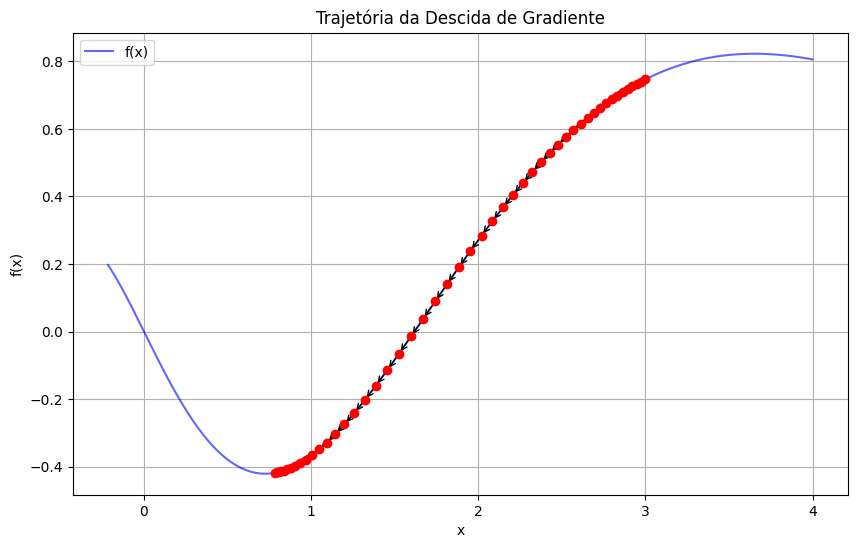

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Definição da função e sua derivada analítica
def f(x):
    return np.exp(-x) * x * (x**2 - x - 1)

def df(x):
    # Derivada calculada: exp(-x) * (-x^3 + 4x^2 - x - 1)
    return np.exp(-x) * (-x**3 + 4.0*x**2 - x - 1.0)

# Parâmetros iniciais
x_k = 3.0
alpha = 0.1
g_min = 0.1
k_max = 100

# Listas para armazenamento dos valores
history_x = [x_k]
history_f = [f(x_k)]
history_df = [df(x_k)]

# Descida de Gradiente
for k in range(k_max):
    grad = df(x_k)
    
    # Condição de parada: Magnitude do gradiente
    if abs(grad) < g_min:
        print(f"Critério de parada atingido: |grad| = {abs(grad):.4f} na iteração {k}")
        break
        
    # Atualização
    x_k = x_k - alpha * grad
    
    # Armazenamento para o gráfico
    history_x.append(x_k)
    history_f.append(f(x_k))
    history_df.append(df(x_k))

print(f"Mínimo aproximado encontrado em x = {x_k:.5f}")
print(f"Valor da função no mínimo f(x) = {f(x_k):.5f}")

# Visualização
x_range = np.linspace(min(history_x) - 1, max(history_x) + 1, 400)
plt.figure(figsize=(10, 6))
plt.plot(x_range, f(x_range), label='f(x)', color='blue', alpha=0.6)

# Plotando a trajetória
plt.scatter(history_x, history_f, color='red', zorder=5)
for i in range(len(history_x)-1):
    plt.annotate('', xy=(history_x[i+1], history_f[i+1]), xytext=(history_x[i], history_f[i]),
                 arrowprops=dict(arrowstyle="->", color='black', lw=1))

# Marcação dos pontos
plt.title('Trajetória da Descida de Gradiente')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()

A execução do algoritmo de descida de gradiente a partir do ponto inicial $x_0 = 3$ demonstrou a convergência bem-sucedida para o mínimo da função. O processo iterativo foi interrompido na **49ª iteração**, momento em que a magnitude do gradiente atingiu $|f'(x)| \approx 0.0894$. Isso satisfez a condição de tolerância da inclinação ($g_{\min} = 0.1$) antes que o limite máximo de passos ($k_{\max} = 100$) fosse alcançado.

O ponto de mínimo aproximado obtido foi **$x \approx 0.78494$**, resultando no valor da função **$f(x) \approx -0.41849$**. 

A análise visual do gráfico gerado confirma esse comportamento: a sequência de marcações em vermelho mapeia a trajetória descendente de $x_k$. Os vetores mostram que os passos de atualização ficaram progressivamente menores à medida que a inclinação da curva diminui, estabilizando a busca exatamente no fundo do vale do mínimo local.

## Q4

Determine pelo menos dois mínimos da função bidimensional:

$$f(x_1, x_2) = \left(4 - 2.1x_1^2 + \frac{x_1^4}{3}\right)x_1^2 + x_1 x_2 + \left(-4 + 4x_2^2\right)x_2^2$$

**a)** Use o método de **diferenças finitas** para aproximar o gradiente $\nabla f$.

**b)** Use o **gradiente explícito** no algoritmo da descida de gradiente.

**c)** Desenhe a trajetória de $x_k$ no plano $(x_1, x_2)$, e o valor da função correspondente $f(x_1, x_2)$ no gráfico 3D.

### a)

In [5]:
import numpy as np

# Definição da função bidimensional
def f(x):
    x1, x2 = x[0], x[1]
    return (4 - 2.1 * x1**2 + (x1**2) / 3) * x1**3 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

# Gradiente por Diferenças Finitas
def grad_f_aprox(x, h=0.01):
    x1, x2 = x[0], x[1]
    
    # Diferença finita para x1
    df_dx1 = (f([x1 + h, x2]) - f([x1, x2])) / h
    # Diferença finita para x2
    df_dx2 = (f([x1, x2 + h]) - f([x1, x2])) / h
    
    return np.array([df_dx1, df_dx2])

# Algoritmo de Descida de Gradiente
def descida_gradiente(x_0, alpha=0.01, g_min=1e-4, max_iter=1000):
    x_k = np.array(x_0, dtype=float)
    
    for _ in range(max_iter):
        grad = grad_f_aprox(x_k)
        
        # Condição de parada pela magnitude do gradiente
        if np.linalg.norm(grad) < g_min:
            break
            
        x_k = x_k - alpha * grad
        
    return x_k, f(x_k)

# Busca por dois mínimos usando pontos iniciais diferentes
ponto_inicial_1 = [1.0, 1.0]
ponto_inicial_2 = [-1.0, -1.0]

min1_x, min1_f = descida_gradiente(ponto_inicial_1)
min2_x, min2_f = descida_gradiente(ponto_inicial_2)

# Exibição dos resultados
print(f"Ponto Inicial 1 {ponto_inicial_1} -> Mínimo em x = [{min1_x[0]:.5f}, {min1_x[1]:.5f}] | f(x) = {min1_f:.5f}")
print(f"Ponto Inicial 2 {ponto_inicial_2} -> Mínimo em x = [{min2_x[0]:.5f}, {min2_x[1]:.5f}] | f(x) = {min2_f:.5f}")

Ponto Inicial 1 [1.0, 1.0] -> Mínimo em x = [-1.19649, 0.76751] | f(x) = -4.40599
Ponto Inicial 2 [-1.0, -1.0] -> Mínimo em x = [-1.14702, -0.62496] | f(x) = -2.76400


Na otimização para o espaço bidimensional o gradiente $\nabla f$ foi obtido calculando as derivadas parciais de forma aproximada usando o método de diferenças finitas separadamente para cada variável ($x_1$ e $x_2$).

Por conta da natureza da função, que apresenta múltiplos vales (mínimos locais), o resultado final depende estritamente do ponto de partida. A execução do algoritmo a partir de duas coordenadas iniciais distintas comprovou esse comportamento:

1. Iniciando no ponto **$[1.0, 1.0]$**, a descida de gradiente convergiu para o mínimo localizado em aproximadamente **$[-1.19649, 0.76751]$**, onde a função atinge o valor de **$-4.40599$**.
2. Partindo de um quadrante oposto, no ponto **$[-1.0, -1.0]$**, a trajetória da atualização encontrou um mínimo local diferente, estabilizando-se em **$[-1.14702, -0.62496]$**, com a função valendo **$-2.76400$**.

Isso demonstra que a técnica baseada em aproximação numérica é viável para múltiplas dimensões, mapeando com sucesso caminhos diferentes até os vales mais próximos de suas respectivas inicializações.

### b)

In [6]:
import numpy as np

# Função original
def f(x):
    x1, x2 = x[0], x[1]
    return (4 - 2.1 * x1**2 + x1**2 / 3) * x1**3 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

# Gradiente Explicito (Analítico)
def grad_f_explicito(x):
    x1, x2 = x[0], x[1]
    
    # Derivadas parciais calculadas analiticamente
    df_dx1 = 12 * x1**2 - (26.5 / 3) * x1**4 + x2
    df_dx2 = x1 - 8 * x2 + 16 * x2**3
    
    return np.array([df_dx1, df_dx2])

# Algoritmo de Descida de Gradiente
def descida_gradiente_explicito(x_0, alpha=0.01, g_min=1e-4, max_iter=1000):
    x_k = np.array(x_0, dtype=float)
    
    for _ in range(max_iter):
        grad = grad_f_explicito(x_k)
        
        # Parada pela magnitude do gradiente
        if np.linalg.norm(grad) < g_min:
            break
            
        x_k = x_k - alpha * grad
        
    return x_k, f(x_k)

# Testando dois pontos iniciais para encontrar mínimos locais distintos
ponto_inicial_1 = [0.5, 0.5]
ponto_inicial_2 = [-0.5, -0.5]

min1_x, min1_f = descida_gradiente_explicito(ponto_inicial_1)
min2_x, min2_f = descida_gradiente_explicito(ponto_inicial_2)

# Resultados
print(f"Ponto Inicial 1 {ponto_inicial_1} -> Mínimo em x = [{min1_x[0]:.5f}, {min1_x[1]:.5f}] | f(x) = {min1_f:.5f}")
print(f"Ponto Inicial 2 {ponto_inicial_2} -> Mínimo em x = [{min2_x[0]:.5f}, {min2_x[1]:.5f}] | f(x) = {min2_f:.5f}")

Ponto Inicial 1 [0.5, 0.5] -> Mínimo em x = [-1.19166, 0.77229] | f(x) = -4.40662
Ponto Inicial 2 [-0.5, -0.5] -> Mínimo em x = [-1.14221, -0.62044] | f(x) = -2.76442


A otimização foi executada utilizando o gradiente analítico (explícito). Ao calcular as derivadas parciais de forma matematicamente exata, não se tem o erro de truncamento presente na aproximação por diferenças finitas, garantindo uma direção de descida mais precisa e computacionalmente eficiente em cada iteração.

Testando a convergência a partir de dois novos pontos de partida mais próximos da origem, o algoritmo confirmou novamente a presença de múltiplos vales na superfície da função:

1. A partir de **$[0.5, 0.5]$**, a busca estabilizou no mínimo localizado em aproximadamente **$[-1.19166, 0.77229]$**, resultando no valor da função **$f(x) \approx -4.40662$**.
2. Partindo de **$[-0.5, -0.5]$**, a trajetória encontrou um mínimo local distinto em **$[-1.14221, -0.62044]$**, com **$f(x) \approx -2.76442$**.

Esses resultados evidenciam que o uso do gradiente explícito mantém o comportamento de convergência dependente da inicialização para funções não-convexas, mas assegura maior rigor matemático e estabilidade no cálculo da atualização dos pesos.

### c)

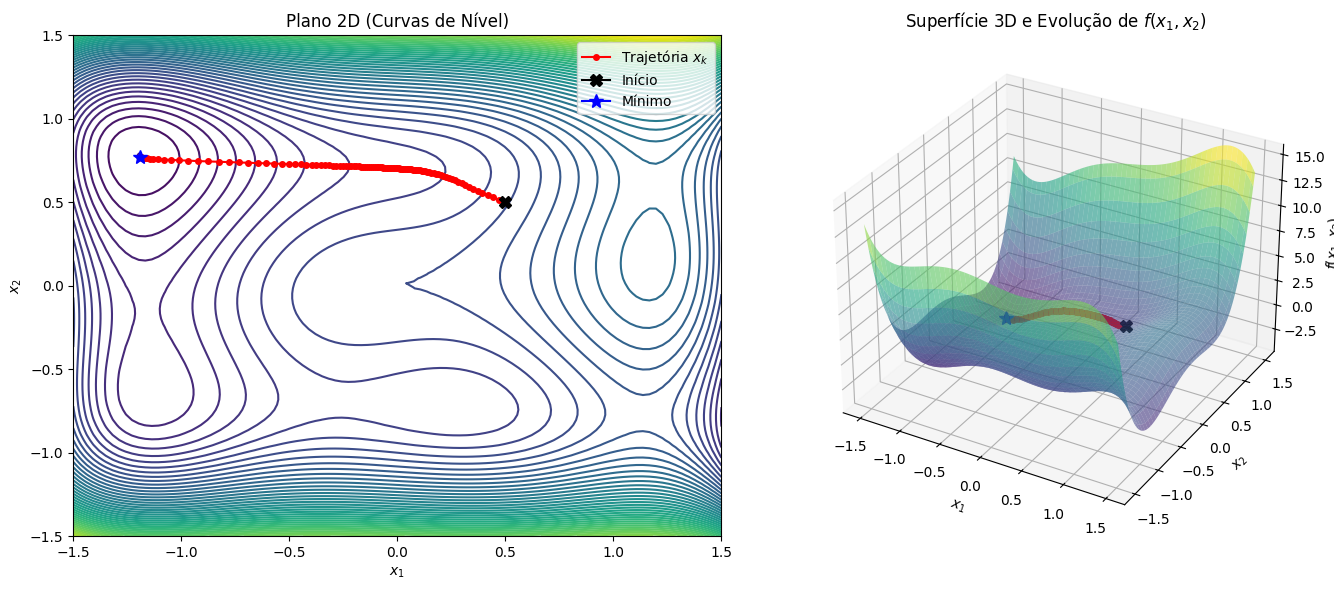

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Definição da função e gradiente
def f(x1, x2):
    return (4 - 2.1 * x1**2 + (x1**2) / 3) * x1**3 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

def grad_f_explicito(x):
    x1, x2 = x[0], x[1]
    df_dx1 = 12 * x1**2 - (26.5 / 3) * x1**4 + x2
    df_dx2 = x1 - 8 * x2 + 16 * x2**3
    return np.array([df_dx1, df_dx2])

# Descida de Gradiente com armazenamento do histórico
def descida_gradiente_historico(x_0, alpha=0.01, g_min=1e-4, max_iter=1000):
    x_k = np.array(x_0, dtype=float)
    hist_x1, hist_x2, hist_f = [x_k[0]], [x_k[1]], [f(x_k[0], x_k[1])]
    
    for _ in range(max_iter):
        grad = grad_f_explicito(x_k)
        if np.linalg.norm(grad) < g_min:
            break
            
        x_k = x_k - alpha * grad
        hist_x1.append(x_k[0])
        hist_x2.append(x_k[1])
        hist_f.append(f(x_k[0], x_k[1]))
        
    return hist_x1, hist_x2, hist_f

# Execução para um ponto inicial
ponto_inicial = [0.5, 0.5]
hx1, hx2, hf = descida_gradiente_historico(ponto_inicial)

# Preparação da malha para os gráficos
X1 = np.linspace(-1.5, 1.5, 100)
X2 = np.linspace(-1.5, 1.5, 100)
X1, X2 = np.meshgrid(X1, X2)
Z = f(X1, X2)

# Plot
fig = plt.figure(figsize=(14, 6))

# Gráfico 1: Trajetória no plano (x1, x2) com curvas de nível
ax1 = fig.add_subplot(1, 2, 1)
cp = ax1.contour(X1, X2, Z, levels=50, cmap='viridis')
ax1.plot(hx1, hx2, marker='o', color='red', markersize=4, label='Trajetória $x_k$')
ax1.plot(hx1[0], hx2[0], marker='X', color='black', markersize=8, label='Início')
ax1.plot(hx1[-1], hx2[-1], marker='*', color='blue', markersize=10, label='Mínimo')
ax1.set_title('Plano 2D (Curvas de Nível)')
ax1.set_xlabel('$x_1$')
ax1.set_ylabel('$x_2$')
ax1.legend()

# Gráfico 2: Trajetória no gráfico 3-D
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.plot_surface(X1, X2, Z, cmap='viridis', alpha=0.6, edgecolor='none')
ax2.plot(hx1, hx2, hf, marker='o', color='red', markersize=4, label='Trajetória $f(x_k)$')
ax2.plot([hx1[0]], [hx2[0]], [hf[0]], marker='X', color='black', markersize=8)
ax2.plot([hx1[-1]], [hx2[-1]], [hf[-1]], marker='*', color='blue', markersize=10)
ax2.set_title('Superfície 3D e Evolução de $f(x_1, x_2)$')
ax2.set_xlabel('$x_1$')
ax2.set_ylabel('$x_2$')
ax2.set_zlabel('$f(x_1, x_2)$')

plt.tight_layout()
plt.show()

A visualização gráfica ilustra de forma intuitiva o comportamento iterativo do algoritmo de otimização na busca pelo mínimo. No gráfico 2D, as curvas de nível mapeiam a topologia da função bidimensional. A trajetória em vermelho mostra os passos sucessivos da descida, sempre em direção ao declive mais acentuado, partindo do ponto inicial $[0.5, 0.5]$ até cruzar o platô e estabilizar no centro do vale local.

O gráfico 3D traduz essa descida espacialmente, demonstrando como os valores deslizam pela superfície não-convexa da função. É possível observar o caminho acompanhando a encosta do relevo até estacionar no ponto mais profundo daquela bacia de atração específica. Ambas as representações comprovam visualmente o sucesso da descida de gradiente em minimizar o valor de $f(x_1, x_2)$ de acordo com a sua inicialização.